# Simple ANN for Satellite Image Classification

Task 1 was chosen for a little local sightseeing from orbit, with the neural network doing the field trip.

## Task as a function

The ANN learns a function from a 200 × 200 RGB patch, normalized to [0, 1], to an estimated probability of urban land: `fθ(x) ≈ P(y = 1 | x)`.

Each training patch has one label (forest = 0, urban = 1); a new patch is classified as urban when `fθ(x) ≥ 0.5`, otherwise as forest.

## Prepare data

Download 1200 × 1200 Sentinel-2 RGB images of Olkusz, Skała, Krzeszowice, Sławków and Wolbrom, assigning whole locations to splits before extracting patches.

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import planetary_computer
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import transform, reproject
from pystac_client import Client

LAB_DIR = Path('lab_4') if Path('lab_4').exists() else Path('.')
IMAGE_DIR = LAB_DIR / 'images'
IMAGE_DIR.mkdir(exist_ok=True)
SIZE = 1200
PATCH_SIZE = 200
STRIDE = 25
SEED = 42
CLASS_NAMES = ['Forest', 'Urban']
COLORS = ['royalblue', 'red']

sites = {
    'olkusz': {'split': 'train', 'lon': 19.56, 'lat': 50.28},
    'skala': {'split': 'validation', 'lon': 19.855, 'lat': 50.23},
    'krzeszowice': {'split': 'train', 'lon': 19.635, 'lat': 50.135},
    'slawkow': {'split': 'validation', 'lon': 19.36, 'lat': 50.285},
    'wolbrom_north': {'split': 'test', 'lon': 19.76, 'lat': 50.41},
}
display(pd.DataFrame(sites).T)

,split,lon,lat
olkusz,train,19.56,50.28
skala,validation,19.855,50.23
krzeszowice,train,19.635,50.135
slawkow,validation,19.36,50.285
wolbrom_north,test,19.76,50.41


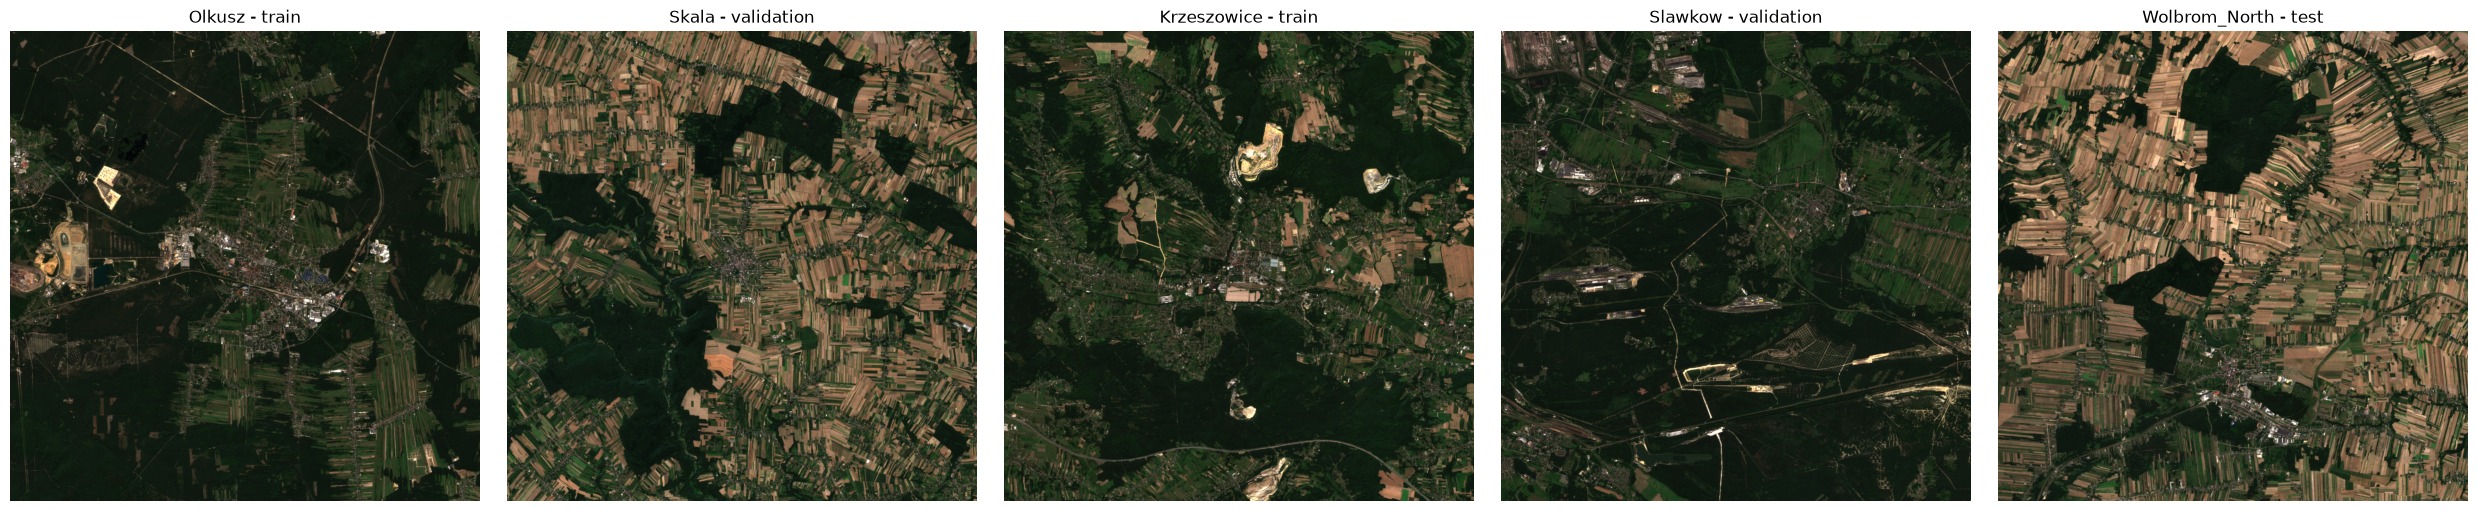

In [27]:
images = {}
catalog = None
for name, site in sites.items():
    path = IMAGE_DIR / f'{name}_sentinel2.png'
    if not path.exists():
        if catalog is None:
            catalog = Client.open('https://planetarycomputer.microsoft.com/api/stac/v1',
                                  modifier=planetary_computer.sign_inplace)
        lon, lat = site['lon'], site['lat']
        search = catalog.search(
            collections=['sentinel-2-l2a'],
            bbox=[lon - 0.01, lat - 0.01, lon + 0.01, lat + 0.01],
            datetime='2024-08-01/2024-08-31',
            query={'eo:cloud_cover': {'lt': 10}},
            sortby=[{'field': 'properties.eo:cloud_cover', 'direction': 'asc'}],
            max_items=8,
        )
        x, y = transform('EPSG:4326', 'EPSG:32634', [lon], [lat])
        grid = from_origin(round(x[0] / 10) * 10 - SIZE * 5,
                           round(y[0] / 10) * 10 + SIZE * 5, 10, 10)
        for item in search.items():
            channels = []
            with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR'):
                for band in ['B04', 'B03', 'B02']:
                    with rasterio.open(item.assets[band].href) as src:
                        out = np.zeros((SIZE, SIZE), dtype=np.uint16)
                        reproject(rasterio.band(src, 1), out,
                                  src_transform=src.transform, src_crs=src.crs,
                                  dst_transform=grid, dst_crs='EPSG:32634')
                    channels.append(out)
            if np.all(np.stack(channels) > 0):
                break
        else:
            raise RuntimeError(f'No complete image for {name}')
        pixels = np.stack(channels, axis=-1).astype(float)
        pixels = np.clip((pixels - 1000) / 3000, 0, 1)
        Image.fromarray((pixels * 255).astype('uint8')).save(path)
    with Image.open(path) as image:
        images[name] = np.array(image.convert('RGB'))

fig, axes = plt.subplots(1, len(sites), figsize=(5*len(sites), 5))
for ax, (name, site) in zip(axes, sites.items()):
    ax.imshow(images[name])
    ax.set_title(f"{name.title()} - {site['split']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Extract labelled patches

Cut 200 × 200 patches from manually labelled forest and urban areas; overlapping patches stay within their location's split, and urban patches may include vegetation.

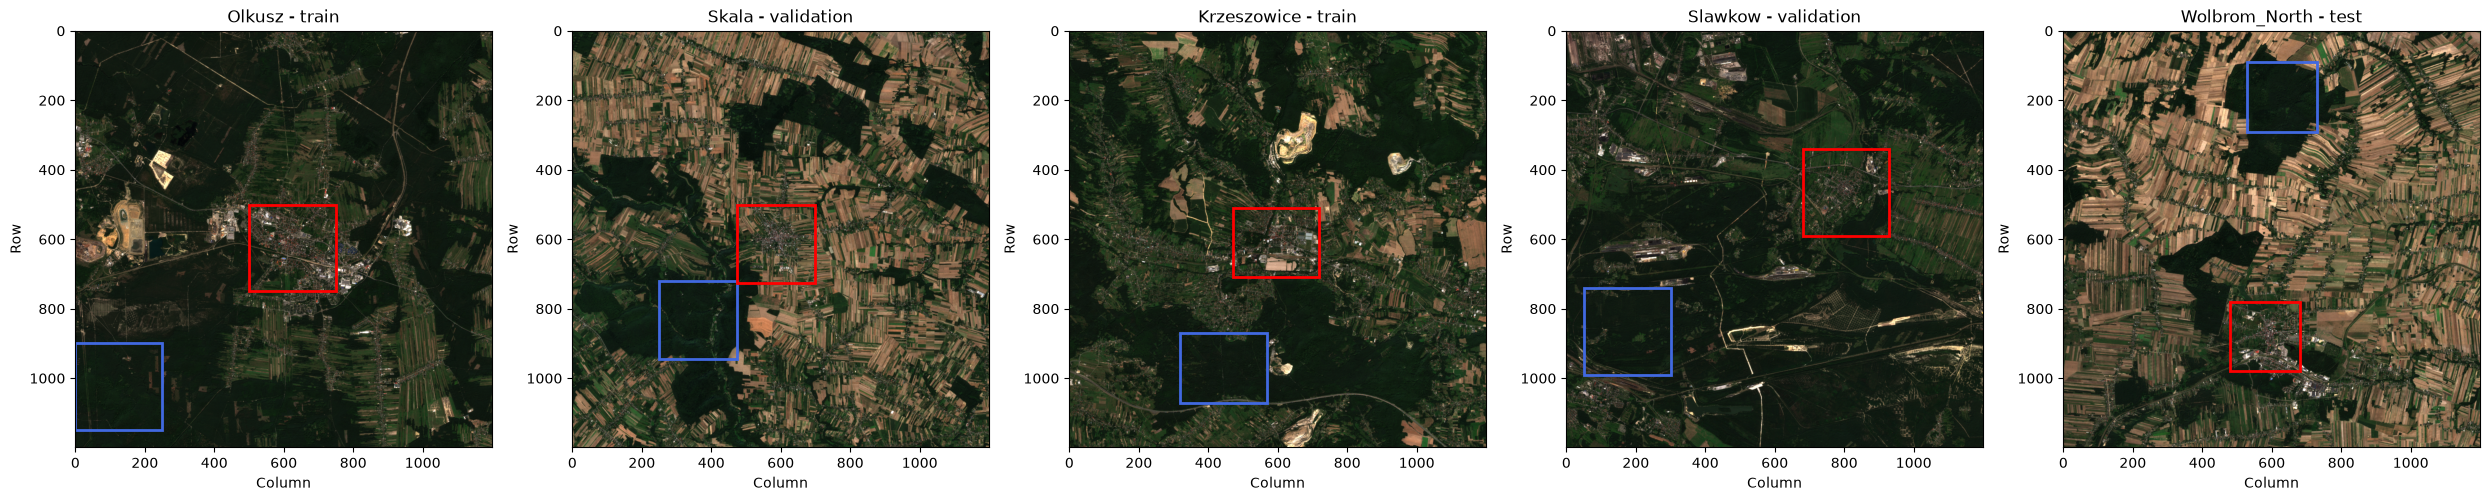

In [28]:
# Boxes: row start, row stop, column start, column stop.
regions = {
    'olkusz': {
        0: [(900, 1150, 0, 250)],
        1: [(500, 750, 500, 750)],
    },
    'skala': {
        0: [(720, 945, 250, 475)],
        1: [(500, 725, 475, 700)],
    },
    'krzeszowice': {
        0: [(870, 1070, 320, 570)],
        1: [(510, 710, 470, 720)],
    },
    'slawkow': {
        0: [(740, 990, 50, 300)],
        1: [(340, 590, 680, 930)],
    },
    'wolbrom_north': {
        0: [(90, 290, 530, 730)],
        1: [(780, 980, 480, 680)],
    },
}

fig, axes = plt.subplots(1, len(sites), figsize=(5*len(sites), 5))
for ax, (name, site) in zip(axes, sites.items()):
    ax.imshow(images[name])
    for label, boxes in regions[name].items():
        for y0, y1, x0, x1 in boxes:
            ax.add_patch(Rectangle((x0, y0), x1-x0, y1-y0,
                                   fill=False, edgecolor=COLORS[label], linewidth=2))
    ax.set_title(f"{name.title()} - {site['split']}")
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')
plt.tight_layout()
plt.show()

,Forest,Urban,Total
train,12,12,24
validation,13,13,26
test,1,1,2


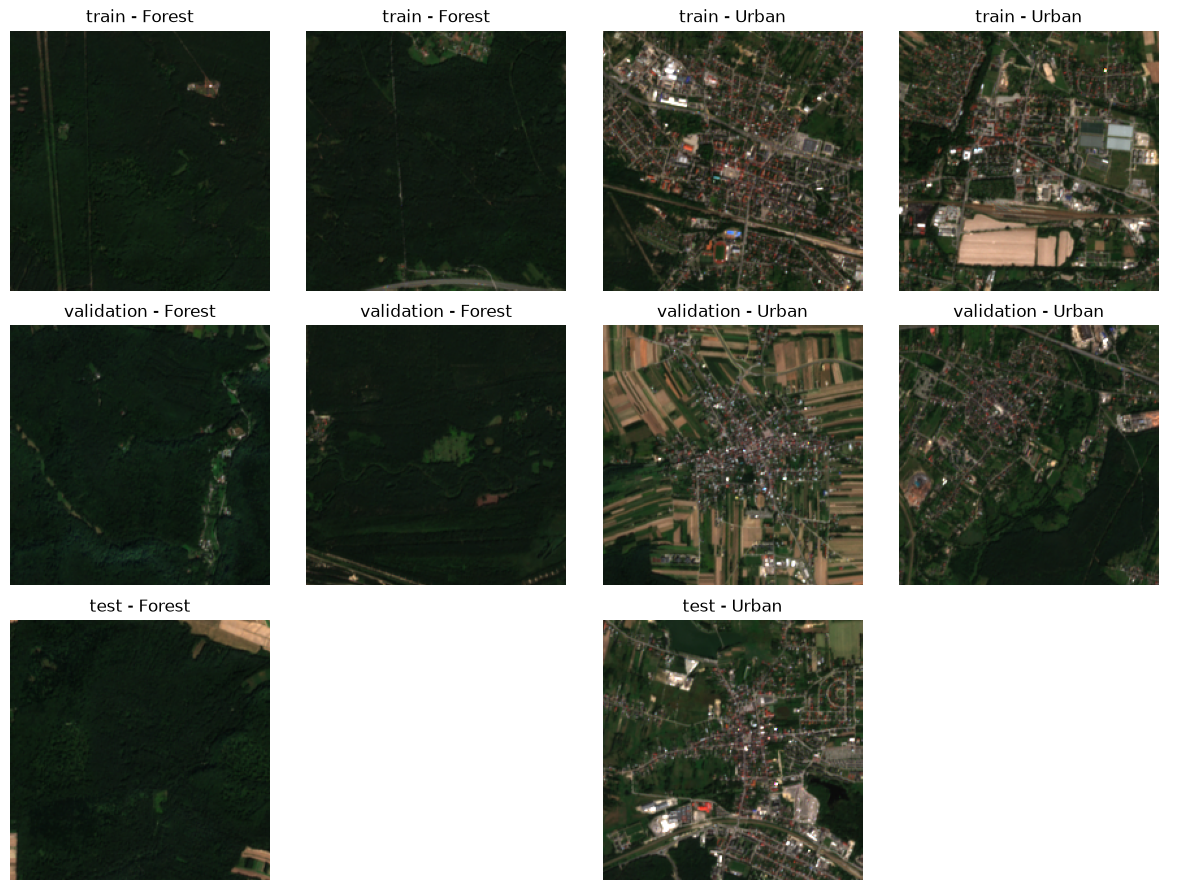

In [29]:
patches = {split: [] for split in ['train', 'validation', 'test']}
labels = {split: [] for split in patches}

for name, site in sites.items():
    split = site['split']
    for label, boxes in regions[name].items():
        for y0, y1, x0, x1 in boxes:
            for row in range(y0, y1 - PATCH_SIZE + 1, STRIDE):
                for col in range(x0, x1 - PATCH_SIZE + 1, STRIDE):
                    patch = images[name][row:row+PATCH_SIZE, col:col+PATCH_SIZE]
                    patches[split].append(patch)
                    labels[split].append(label)

X = {split: np.stack(items) for split, items in patches.items()}
y = {split: np.array(items) for split, items in labels.items()}
counts = pd.DataFrame({
    split: np.bincount(y[split], minlength=2) for split in y
}, index=CLASS_NAMES).T
counts['Total'] = counts.sum(axis=1)
display(counts)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, split in enumerate(X):
    for ax in axes[row]:
        ax.axis('off')
    for label in [0, 1]:
        indices = np.flatnonzero(y[split] == label)
        for example, index in enumerate(np.unique(indices[[0, -1]])):
            ax = axes[row, 2*label + example]
            ax.imshow(X[split][index])
            ax.set_title(f'{split} - {CLASS_NAMES[label]}')
plt.tight_layout()
plt.show()

The dataset is a small demonstration with correlated overlapping patches; class counts are patch counts, not independent locations.

## Normalize data

Convert RGB values to float32 and divide by 255 for every split, then set the random seed for reproducible training.

In [30]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)
X_normalized = {split: pixels.astype(np.float32) / 255.0 for split, pixels in X.items()}

X_train, y_train = X_normalized['train'], y['train']
X_validation, y_validation = X_normalized['validation'], y['validation']
X_test, y_test = X_normalized['test'], y['test']

display(pd.DataFrame([
    {'split': split, 'shape': pixels.shape, 'dtype': str(pixels.dtype),
     'min': float(pixels.min()), 'max': float(pixels.max())}
    for split, pixels in X_normalized.items()
]))

,split,shape,dtype,min,max
0,train,"(24, 200, 200, 3)",float32,0.000000,1.0
1,validation,"(26, 200, 200, 3)",float32,0.015686,1.0
2,test,"(2, 200, 200, 3)",float32,0.000000,1.0


## Network architecture

We use a **multilayer perceptron (MLP)** with one hidden layer as a simple baseline for binary patch classification.

| Layer | Output shape | Purpose |
| --- | --- | --- |
| Input | 200 × 200 × 3 | Normalized RGB patch. |
| Flatten | 120,000 | Convert the patch into a vector. |
| Dense, ReLU | 16 | Learn nonlinear combinations of pixel values. |
| Dense, sigmoid | 1 | Estimate the probability of urban land. |

**Training:** binary cross-entropy measures prediction error, Adam updates the weights with a learning rate of 0.001, and accuracy measures correct class predictions at a threshold of 0.5.

The model has **1,920,033 trainable parameters**, so this small regional dataset still carries a high risk of overfitting.

## Train five variants

Train each configuration for 50 epochs with batch size 2 and seed 42, then compare final-epoch validation accuracy against the balanced-class baseline of 50%.

In [31]:
from time import perf_counter

EPOCHS = 50
BATCH_SIZE = 2
LEARNING_RATE = 0.001
configurations = [
    {'name': '16 / Adam', 'hidden_layers': (16,), 'optimizer': 'adam'},
    {'name': '32 / Adam', 'hidden_layers': (32,), 'optimizer': 'adam'},
    {'name': '64 / Adam', 'hidden_layers': (64,), 'optimizer': 'adam'},
    {'name': '32-16 / Adam', 'hidden_layers': (32, 16), 'optimizer': 'adam'},
    {'name': '32-16 / SGD', 'hidden_layers': (32, 16), 'optimizer': 'sgd'},
]

def build_model(hidden_layers, optimizer_name):
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(PATCH_SIZE, PATCH_SIZE, 3)),
        tf.keras.layers.Flatten(),
    ])
    for units in hidden_layers:
        model.add(tf.keras.layers.Dense(units, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    optimizer = (tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
                 if optimizer_name == 'adam'
                 else tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE))
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

models, histories = {}, {}
rows = []
for config in configurations:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    name = config['name']
    model = build_model(config['hidden_layers'], config['optimizer'])
    start = perf_counter()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_validation, y_validation),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=0,
    )
    seconds = perf_counter() - start
    models[name] = model
    histories[name] = history.history
    rows.append({
        'variant': name,
        'parameters': model.count_params(),
        'training accuracy': history.history['accuracy'][-1],
        'validation accuracy': history.history['val_accuracy'][-1],
        'training loss': history.history['loss'][-1],
        'validation loss': history.history['val_loss'][-1],
        'training time (s)': seconds,
    })
    print(f'{name}: finished in {seconds:.1f} s', flush=True)

16 / Adam: finished in 8.8 s
32 / Adam: finished in 16.4 s
64 / Adam: finished in 29.7 s
32-16 / Adam: finished in 15.8 s
32-16 / SGD: finished in 6.9 s


## Compare training results

Validation metrics use a threshold of 0.5 and equal class weights for macro scores; rows retain experiment order.

In [32]:
from sklearn.metrics import balanced_accuracy_score, precision_recall_fscore_support

results = pd.DataFrame(rows).set_index('variant')
validation_predictions = {}

for name, model in models.items():
    probabilities = model(X_validation, training=False).numpy().ravel()
    predictions = (probabilities >= 0.5).astype(int)
    validation_predictions[name] = predictions
    precision, recall, f1, support = precision_recall_fscore_support(
        y_validation, predictions, labels=[0, 1], zero_division=0,
    )
    results.loc[name, 'balanced accuracy'] = balanced_accuracy_score(y_validation, predictions)
    results.loc[name, 'precision (macro)'] = precision.mean()
    results.loc[name, 'recall (macro)'] = recall.mean()
    results.loc[name, 'F1 (macro)'] = f1.mean()

display(results[[
    'training accuracy', 'validation accuracy', 'balanced accuracy',
    'precision (macro)', 'recall (macro)', 'F1 (macro)',
    'validation loss', 'training time (s)',
]].round(4))

,training accuracy,validation accuracy,balanced accuracy,precision (macro),recall (macro),F1 (macro),validation loss,training time (s)
variant,,,,,,,,
16 / Adam,1.0,0.6538,0.6538,0.7955,0.6538,0.6067,2.8979,8.8262
32 / Adam,0.5,0.5000,0.5000,0.2500,0.5000,0.3333,0.6933,16.3894
64 / Adam,1.0,0.6538,0.6538,0.7955,0.6538,0.6067,10.2926,29.6781
32-16 / Adam,1.0,0.6154,0.6154,0.7826,0.6154,0.5486,2.2799,15.8238
32-16 / SGD,1.0,0.6538,0.6538,0.7955,0.6538,0.6067,1.3553,6.8959


## Conclusions

SGD provided the best overall trade-off, combining 65.4% validation accuracy and a macro-F1 of 0.607 with the shortest training time.
The 16-neuron Adam model was a close alternative, matching accuracy and F1 but taking longer and producing a higher validation loss.
Wider or deeper Adam networks did not improve validation accuracy or F1.
Most variants reached 100% training accuracy but only 50–65.4% validation accuracy, indicating overfitting on this small dataset.